# Experiment No.9: K-Means Clustering Algorithm

# Cell 1: Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Cell 2: Load the dataset

In [3]:
df = pd.read_csv("Mall_Customers.csv")

print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


# Cell 3: Display dataset information

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200, 5)

Column Names:
Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Cell 4: Select features

In [5]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print(X.head())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


# Cell 5: Visualize the original data

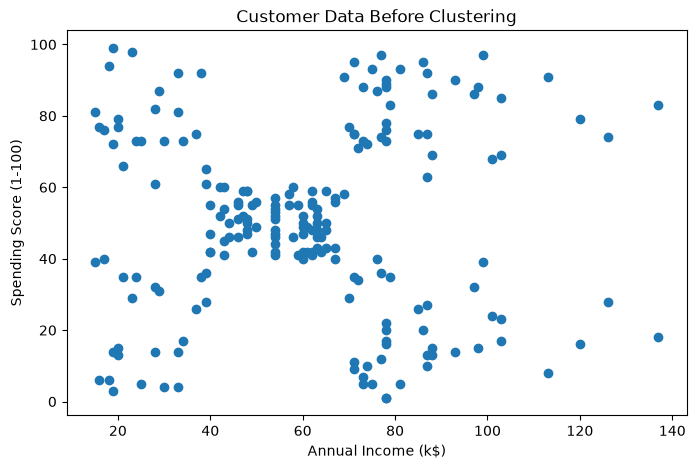

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)']
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Data Before Clustering')

plt.show()

# Cell 6: Apply K-Means clustering

In [7]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X)

df['Cluster'] = kmeans.labels_

print(df.head(10))

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        2  
1        2  
2        2  
3        2  
4        2  
5        2  
6        2  
7        2  
8        2  
9        2  


# Cell 7: Display cluster centroids

In [8]:
print("Cluster Centroids:")

print(kmeans.cluster_centers_)

Cluster Centroids:
[[87.         18.63157895]
 [86.53846154 82.12820513]
 [44.15447154 49.82926829]]


# Cell 8: Visualize the final clusters

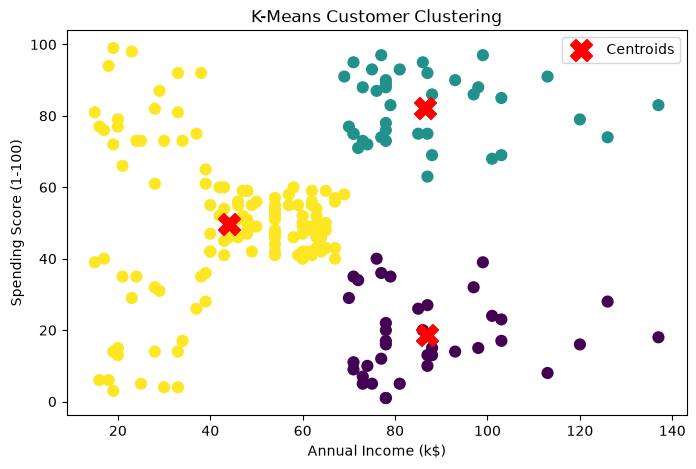

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=kmeans.labels_,
    cmap='viridis',
    s=60
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=250,
    label='Centroids'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('K-Means Customer Clustering')
plt.legend()
plt.show()

# Cell 9: Calculate WCSS

In [10]:
print("WCSS (Inertia):", kmeans.inertia_)

WCSS (Inertia): 106348.37306211119


# Cell 10: Apply the Elbow Method

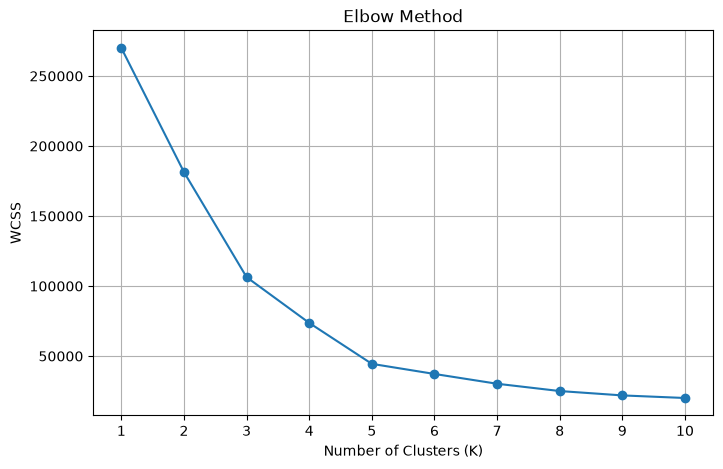

In [11]:
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# Cell 11: Display the final clustered dataset

In [12]:
print("Final Clustered Dataset:")

print(df.head(10))

print("\nNumber of Clusters:", df['Cluster'].nunique())

print("\nCustomers in Each Cluster:")

print(df['Cluster'].value_counts().sort_index())

Final Clustered Dataset:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        2  
1        2  
2        2  
3        2  
4        2  
5        2  
6        2  
7        2  
8        2  
9        2  

Number of Cluste

# Cell 12: Save the result to a CSV file

In [13]:
df.to_csv("Mall_Customers_Clustered.csv", index=False)

print("Clustered dataset saved successfully!")

Clustered dataset saved successfully!
